# Task 01 - Exploratory Data Analysis: Supermarket Sales
**Devixo Solutions - Data Science Internship Program**

**Dataset:** Supermarket Sales (Kaggle) - 1,000 transactions from three branches (Yangon, Mandalay, Naypyitaw), January to March 2019.

**Goal:** go through the full EDA workflow: understand the data, clean it, analyse the features, check correlations, visualise patterns, and turn the findings into business insights and recommendations.

I wrote a short note before each section explaining *why* I am doing that step, so the notebook reads as a story and not only as code.

## Part 1 - Data Import & Understanding
First I load the file and look at its basic structure. Before analysing anything I need to know how many rows and columns there are, what each column holds, and whether Python read the types correctly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os, warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
os.makedirs('graphs', exist_ok=True)

def save(name):
    # one helper so every graph is saved as an image for the report
    plt.tight_layout()
    plt.savefig(f'graphs/{name}.png', dpi=130, bbox_inches='tight')
    plt.show()

df = pd.read_csv('data/supermarket_sales.csv')
print('Loaded OK')

Loaded OK


In [2]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [3]:
df.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,13:46,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,17:16,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2/9/2019,13:22,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2/22/2019,15:33,Cash,65.82,4.761905,3.2910,4.1
999,849-09-3807,A,Yangon,Member,Female,Fashion accessories,88.34,7,30.9190,649.2990,2/18/2019,13:28,Cash,618.38,4.761905,30.9190,6.6


In [4]:
print('Shape (rows, columns):', df.shape)

Shape (rows, columns): (1000, 17)


In [5]:
print(list(df.columns))

['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


In [6]:
df.dtypes

Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

In [7]:
numerical_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(exclude='number').columns.tolist()
print('Numerical  :', numerical_cols)
print()
print('Categorical:', categorical_cols)

Numerical  : ['Unit price', 'Quantity', 'Tax 5%', 'Total', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Categorical: ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Date', 'Time', 'Payment']


`Date` and `Time` are stored as plain text, so I will convert them later. `Invoice ID` is only an identifier, not a real feature.

In [8]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.672,26.495,10.080,32.875,55.230,77.935,99.960
Quantity,1000.0,5.510,2.923,1.000,3.000,5.000,8.000,10.000
Tax 5%,1000.0,15.379,11.709,0.508,5.925,12.088,22.445,49.650
Total,1000.0,322.967,245.885,10.678,124.422,253.848,471.350,1042.650
cogs,1000.0,307.587,234.177,10.170,118.498,241.760,448.905,993.000
gross margin percentage,1000.0,4.762,0.000,4.762,4.762,4.762,4.762,4.762
gross income,1000.0,15.379,11.709,0.508,5.925,12.088,22.445,49.650
Rating,1000.0,6.973,1.719,4.000,5.500,7.000,8.500,10.000


In [9]:
df.describe(include='object').T

,count,unique,top,freq
Invoice ID,1000,1000,750-67-8428,1
Branch,1000,3,A,340
City,1000,3,Yangon,340
Customer type,1000,2,Member,501
Gender,1000,2,Female,501
Product line,1000,6,Fashion accessories,178
Date,1000,89,2/7/2019,20
Time,1000,506,19:48,7
Payment,1000,3,Ewallet,345


## Part 2 - Data Cleaning
Cleaning comes before any analysis because wrong or messy data leads to wrong conclusions. I check for missing values, duplicates, wrong data types and inconsistent values, and I explain each decision.

In [10]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nTotal missing:', df.isnull().sum().sum())

Missing values per column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Total missing: 0


**Decision:** there are no missing values, so nothing needs to be filled or dropped. Imputing values that do not exist would only add noise.

In [11]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Invoice IDs:', df['Invoice ID'].duplicated().sum())

Duplicate rows: 0
Duplicate Invoice IDs: 0


**Decision:** no duplicate rows and every Invoice ID is unique, so each row is exactly one transaction and nothing is removed.

In [12]:
# Date and Time are text -> convert them, and build time features I will need later
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M').dt.hour
df['Month'] = df['Date'].dt.month_name()
df['Weekday'] = df['Date'].dt.day_name()
df['Week'] = df['Date'].dt.to_period('W').dt.start_time
df.dtypes

Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                       datetime64[us]
Time                                  str
Payment                               str
cogs                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
Hour                                int32
Month                                 str
Weekday                               str
Week                       datetime64[us]
dtype: object

**Decision:** converted `Date` to a real datetime type and created `Hour`, `Month`, `Weekday` and `Week` so I can study time patterns.

In [13]:
# Inconsistent values: look at the labels of every categorical column
for col in ['Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Payment']:
    print(col, '->', sorted(df[col].unique()))
print()
# Are there stray spaces or case problems?
for col in ['Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Payment']:
    assert (df[col] == df[col].str.strip()).all()
print('No leading/trailing space problems.')
print('Branch/City mapping:'); print(df.groupby('Branch')['City'].unique())

Branch -> ['A', 'B', 'C']
City -> ['Mandalay', 'Naypyitaw', 'Yangon']
Customer type -> ['Member', 'Normal']
Gender -> ['Female', 'Male']
Product line -> ['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']
Payment -> ['Cash', 'Credit card', 'Ewallet']

No leading/trailing space problems.
Branch/City mapping:
Branch
A       [Yangon]
B     [Mandalay]
C    [Naypyitaw]
Name: City, dtype: object


**Decision:** labels are consistent. Each Branch maps to exactly one City, so these two columns carry the same information.

In [14]:
# Invalid values: do the money columns follow the dataset's own rules?
print('Unit price range :', df['Unit price'].min(), '-', df['Unit price'].max())
print('Quantity range   :', df['Quantity'].min(), '-', df['Quantity'].max())
print('Rating range     :', df['Rating'].min(), '-', df['Rating'].max())
print('Any negative values:', (df[['Unit price','Quantity','Total','cogs']] < 0).any().any())

print('\ncogs == unit price x quantity      :', np.allclose(df['cogs'], df['Unit price']*df['Quantity']))
print('Tax 5% == 5% of cogs               :', np.allclose(df['Tax 5%'], 0.05*df['cogs']))
print('Total == cogs + tax                :', np.allclose(df['Total'], df['cogs'] + df['Tax 5%']))
print('gross income == Tax 5%             :', np.allclose(df['gross income'], df['Tax 5%']))
print('gross margin % unique values       :', df['gross margin percentage'].unique())

Unit price range : 10.08 - 99.96
Quantity range   : 1 - 10
Rating range     : 4.0 - 10.0
Any negative values: False

cogs == unit price x quantity      : True
Tax 5% == 5% of cogs               : True
Total == cogs + tax                : True
gross income == Tax 5%             : True
gross margin % unique values       : [4.76190476]


**Important finding from cleaning:** the money columns are all calculated from each other.
- `cogs` = unit price x quantity, so it is just the pre-tax sale amount.
- `Total` = `cogs` + tax.
- `gross income` is an exact copy of `Tax 5%`.
- `gross margin percentage` is the same constant (4.7619%) in every row.

So `gross income` and `gross margin percentage` do not describe real profit differences between products or branches. I keep `Total` as my revenue measure and leave the constant column out of correlation analysis, because a column that never changes cannot correlate with anything.

In [15]:
# Verify the dataset after cleaning
print('Shape:', df.shape)
print('Missing:', df.isnull().sum().sum(), '| Duplicates:', df.duplicated().sum())
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date(), '(', df['Date'].nunique(), 'trading days )')
df.info()

Shape: (1000, 21)
Missing: 0 | Duplicates: 0
Date range: 2019-01-01 to 2019-03-30 ( 89 trading days )
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   str           
 1   Branch                   1000 non-null   str           
 2   City                     1000 non-null   str           
 3   Customer type            1000 non-null   str           
 4   Gender                   1000 non-null   str           
 5   Product line             1000 non-null   str           
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Total                    1000 non-null   float64       
 10  Date                     1000 non-null   datetime64[us]
 11  Time 

## Part 3 - Feature Analysis
Now I look at each important feature: min, max, average, distribution, important categories and outliers.

In [16]:
num_features = ['Unit price', 'Quantity', 'Total', 'Rating']
summary = df[num_features].agg(['min', 'max', 'mean', 'median', 'std', 'skew']).T.round(2)
summary

,min,max,mean,median,std,skew
Unit price,10.08,99.96,55.67,55.23,26.49,0.01
Quantity,1.00,10.00,5.51,5.00,2.92,0.01
Total,10.68,1042.65,322.97,253.85,245.89,0.89
Rating,4.00,10.00,6.97,7.00,1.72,0.01


`Total` has a mean (322.97) clearly above its median (253.85) and a skew of about 0.89, so a few large baskets pull the average up. `Unit price`, `Quantity` and `Rating` are almost perfectly symmetric (skew near 0), which fits values spread evenly across a range.

In [17]:
# Categorical features: counts and share
for col in ['Branch', 'Customer type', 'Gender', 'Product line', 'Payment']:
    t = df[col].value_counts()
    print(pd.DataFrame({'count': t, 'share %': (t/len(df)*100).round(1)}))
    print()

        count  share %
Branch                
A         340     34.0
B         332     33.2
C         328     32.8

               count  share %
Customer type                
Member           501     50.1
Normal           499     49.9

        count  share %
Gender                
Female    501     50.1
Male      499     49.9

                        count  share %
Product line                          
Fashion accessories       178     17.8
Food and beverages        174     17.4
Electronic accessories    170     17.0
Sports and travel         166     16.6
Home and lifestyle        160     16.0
Health and beauty         152     15.2

             count  share %
Payment                    
Ewallet        345     34.5
Cash           344     34.4
Credit card    311     31.1



In [18]:
# Outliers with the IQR rule
rows = []
for col in num_features:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low,2), round(high,2), n])
pd.DataFrame(rows, columns=['Feature', 'Lower fence', 'Upper fence', 'Outliers'])

,Feature,Lower fence,Upper fence,Outliers
0,Unit price,-34.72,145.53,0
1,Quantity,-4.50,15.50,0
2,Total,-395.97,991.74,9
3,Rating,1.00,13.00,0


In [19]:
q1, q3 = df['Total'].quantile([0.25, 0.75]); upper = q3 + 1.5*(q3 - q1)
print('Upper fence for Total:', round(upper, 2))
print(df.loc[df['Total'] > upper, ['Invoice ID','Branch','Product line','Unit price','Quantity','Total']].sort_values('Total', ascending=False))
share = df.nlargest(100, 'Total')['Total'].sum() / df['Total'].sum() * 100
print(f'\nTop 100 transactions (top 10 percent) share of revenue: {share:.1f} percent')

Upper fence for Total: 991.74
      Invoice ID Branch         Product line  Unit price  Quantity     Total
350  860-79-0874      C  Fashion accessories       99.30        10  1042.650
167  687-47-8271      A  Fashion accessories       98.98        10  1039.290
557  283-26-5248      C   Food and beverages       98.52        10  1034.460
699  751-41-9720      C   Home and lifestyle       97.50        10  1023.750
996  303-96-2227      B   Home and lifestyle       97.38        10  1022.490
792  744-16-7898      B   Home and lifestyle       97.37        10  1022.385
422  271-88-8734      C  Fashion accessories       97.21        10  1020.705
166  234-65-2137      C   Home and lifestyle       95.58        10  1003.590
357  554-42-2417      C    Sports and travel       95.44        10  1002.120

Top 100 transactions (top 10 percent) share of revenue: 25.9 percent


Only `Total` has outliers (9 baskets above the upper fence). They are all high-quantity, high-price purchases (price x quantity naturally reaches about 1,000), so they are genuine big purchases and **not errors**. I keep them.

In [20]:
# Which features look most important for the business question (what drives revenue / satisfaction)?
by = lambda c: df.groupby(c).agg(transactions=('Total','size'), revenue=('Total','sum'),
                                  avg_basket=('Total','mean'), avg_rating=('Rating','mean')).round(2)
for c in ['Branch', 'Product line', 'Customer type', 'Gender', 'Payment']:
    print(by(c).sort_values('revenue', ascending=False)); print()

        transactions    revenue  avg_basket  avg_rating
Branch                                                 
C                328  110568.71      337.10        7.07
A                340  106200.37      312.35        7.03
B                332  106197.67      319.87        6.82



                        transactions   revenue  avg_basket  avg_rating
Product line                                                          
Food and beverages               174  56144.84      322.67        7.11
Sports and travel                166  55122.83      332.07        6.92
Electronic accessories           170  54337.53      319.63        6.92
Fashion accessories              178  54305.90      305.09        7.03
Home and lifestyle               160  53861.91      336.64        6.84
Health and beauty                152  49193.74      323.64        7.00

               transactions    revenue  avg_basket  avg_rating
Customer type                                                 
Member                  501  164223.44      327.79        6.94
Normal                  499  158743.30      318.12        7.01



        transactions    revenue  avg_basket  avg_rating
Gender                                                 
Female           501  167882.92      335.10        6.96
Male             499  155083.82      310.79        6.98

             transactions    revenue  avg_basket  avg_rating
Payment                                                     
Cash                  344  112206.57      326.18        6.97
Ewallet               345  109993.11      318.82        6.95
Credit card           311  100767.07      324.01        7.00



## Part 4 - Correlation Analysis
Correlation tells me which numbers move together. I leave out the constant `gross margin percentage`, and I also leave out `cogs`, `Tax 5%` and `gross income` because they are formulas of price x quantity and would just show up as perfect correlations.

In [21]:
corr_cols = ['Unit price', 'Quantity', 'Total', 'Rating', 'Hour']
corr = df[corr_cols].corr().round(3)
corr

,Unit price,Quantity,Total,Rating,Hour
Unit price,1.000,0.011,0.634,-0.009,0.008
Quantity,0.011,1.000,0.706,-0.016,-0.007
Total,0.634,0.706,1.000,-0.036,-0.003
Rating,-0.009,-0.016,-0.036,1.000,-0.031
Hour,0.008,-0.007,-0.003,-0.031,1.000


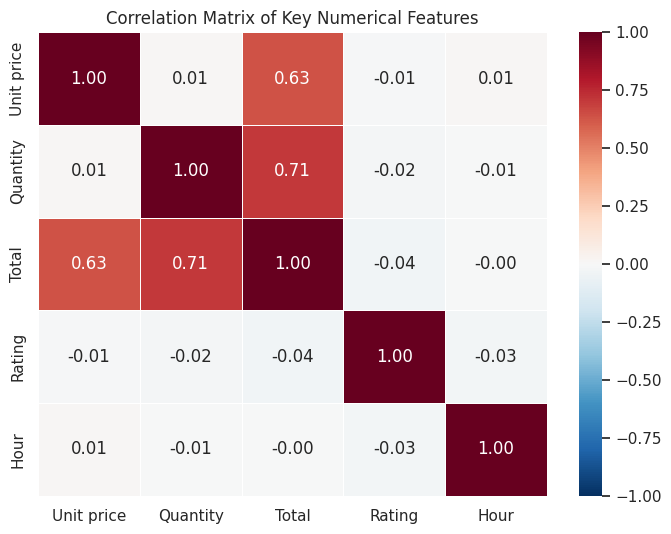

In [22]:
plt.figure(figsize=(7,5.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1, fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Key Numerical Features')
save('01_correlation_heatmap')

In [23]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print(pairs)

Quantity    Total         0.706
Unit price  Total         0.634
Total       Rating       -0.036
Rating      Hour         -0.031
Quantity    Rating       -0.016
Unit price  Quantity      0.011
            Rating       -0.009
            Hour          0.008
Quantity    Hour         -0.007
Total       Hour         -0.003
Unit price  Unit price      NaN
Quantity    Unit price      NaN
            Quantity        NaN
Total       Unit price      NaN
            Quantity        NaN
            Total           NaN
Rating      Unit price      NaN
            Quantity        NaN
            Total           NaN
            Rating          NaN
Hour        Unit price      NaN
            Quantity        NaN
            Total           NaN
            Rating          NaN
            Hour            NaN
dtype: float64


**What the correlation shows**
- **Strong positive:** `Quantity` and `Total` (r = 0.71), `Unit price` and `Total` (r = 0.63). This is expected: the basket value is price x quantity.
- **Strong negative:** none. The most negative value is `Total` vs `Rating` at -0.04, which is essentially zero.
- **Weak / none:** `Rating` is not related to anything (|r| < 0.04 with price, quantity, total or hour). `Unit price` and `Quantity` are also unrelated to each other (r = 0.01), meaning customers do not buy fewer items when the price is higher.
- **Most important relationship:** basket size is driven by *both* how many items and how expensive they are, independently.

## Part 5 - Data Visualization
I created 16 graphs. Each one answers a specific question, and I wrote the reading under it.

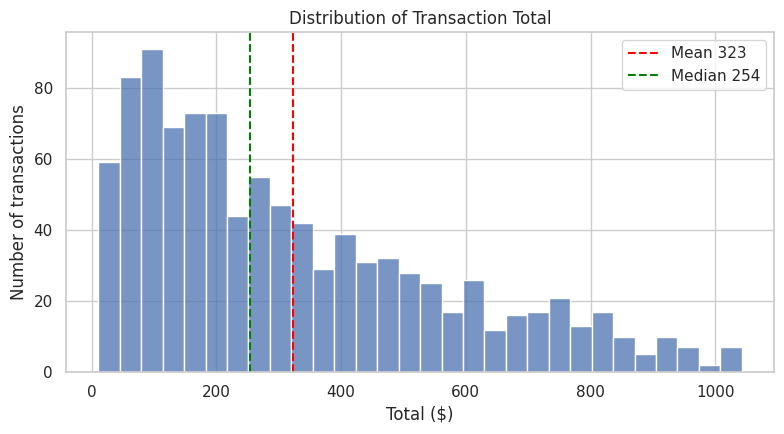

In [24]:
# 1. Histogram - how big are baskets?
plt.figure(figsize=(8,4.5))
sns.histplot(df['Total'], bins=30, color='#4C72B0')
plt.axvline(df['Total'].mean(), color='red', ls='--', label=f"Mean {df['Total'].mean():.0f}")
plt.axvline(df['Total'].median(), color='green', ls='--', label=f"Median {df['Total'].median():.0f}")
plt.title('Distribution of Transaction Total'); plt.xlabel('Total ($)'); plt.ylabel('Number of transactions'); plt.legend()
save('02_hist_total')

Most baskets are small to medium and the right tail stretches towards $1,000. The mean sits above the median because of that tail.

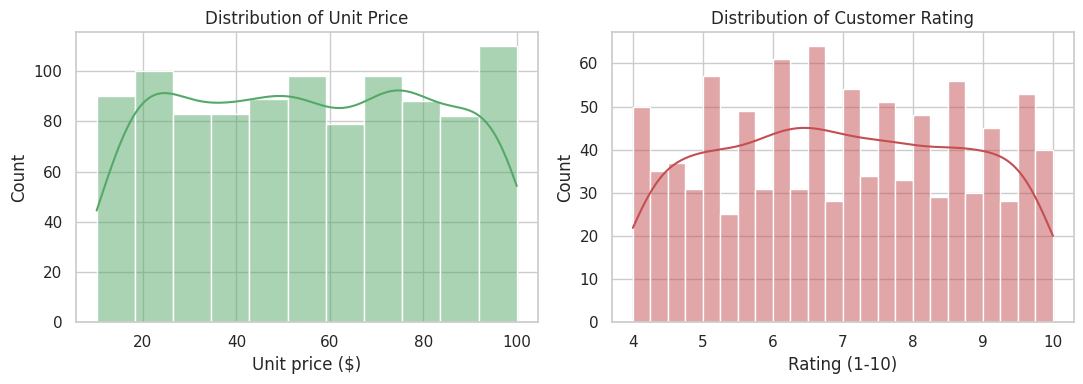

In [25]:
# 2. Distribution plots - unit price and rating
fig, ax = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(df['Unit price'], kde=True, ax=ax[0], color='#55A868'); ax[0].set_title('Distribution of Unit Price'); ax[0].set_xlabel('Unit price ($)')
sns.histplot(df['Rating'], kde=True, ax=ax[1], color='#C44E52', bins=24); ax[1].set_title('Distribution of Customer Rating'); ax[1].set_xlabel('Rating (1-10)')
save('03_dist_price_rating')

Prices are spread fairly evenly between $10 and $100, and ratings are spread evenly between 4 and 10. Nobody rated below 4, and the ratings do not cluster around any single score.

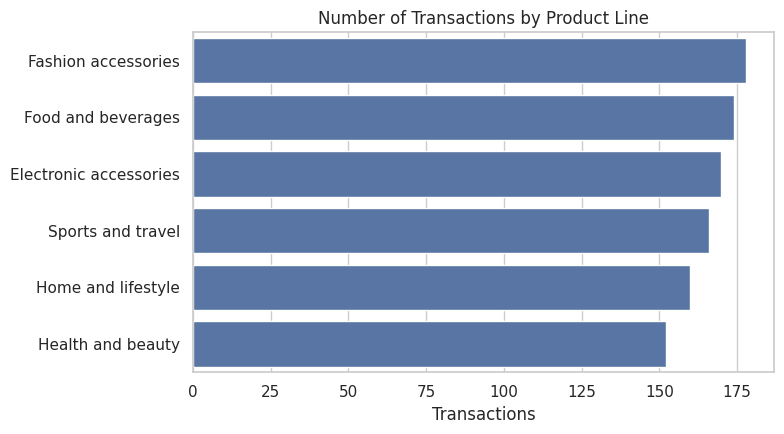

In [26]:
# 3. Count plot - transactions per product line
plt.figure(figsize=(8,4.5))
order = df['Product line'].value_counts().index
sns.countplot(data=df, y='Product line', order=order, color='#4C72B0')
plt.title('Number of Transactions by Product Line'); plt.xlabel('Transactions'); plt.ylabel('')
save('04_count_product')

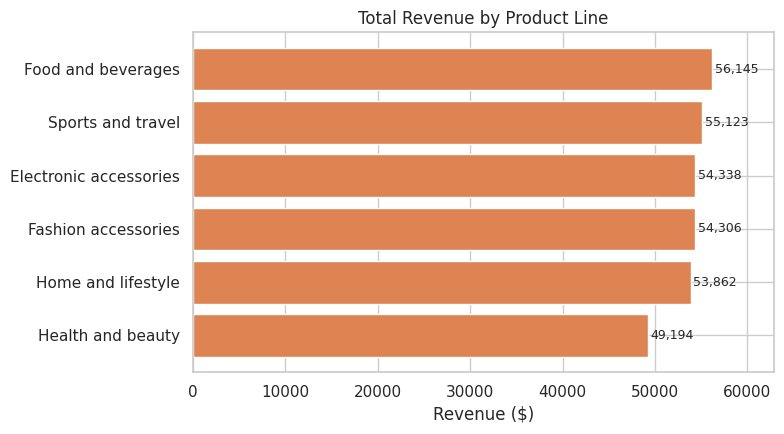

In [27]:
# 4. Bar chart - revenue per product line
rev = df.groupby('Product line')['Total'].sum().sort_values()
plt.figure(figsize=(8,4.5))
bars = plt.barh(rev.index, rev.values, color='#DD8452')
for b, v in zip(bars, rev.values): plt.text(v+300, b.get_y()+b.get_height()/2, f'{v:,.0f}', va='center', fontsize=9)
plt.title('Total Revenue by Product Line'); plt.xlabel('Revenue ($)'); plt.xlim(0, rev.max()*1.12)
save('05_bar_revenue_product')

Food and beverages earns the most ($56.1k) and Health and beauty the least ($49.2k). The gap comes from the number of transactions (174 vs 152), not from bigger baskets.

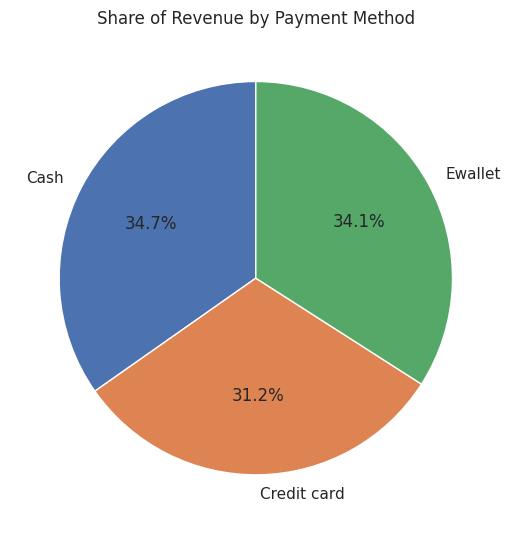

In [28]:
# 5. Pie chart - payment methods share of revenue
pay = df.groupby('Payment')['Total'].sum()
plt.figure(figsize=(5.5,5.5))
plt.pie(pay, labels=pay.index, autopct='%1.1f%%', startangle=90, colors=['#4C72B0','#DD8452','#55A868'], wedgeprops={'edgecolor':'white'})
plt.title('Share of Revenue by Payment Method')
save('06_pie_payment')

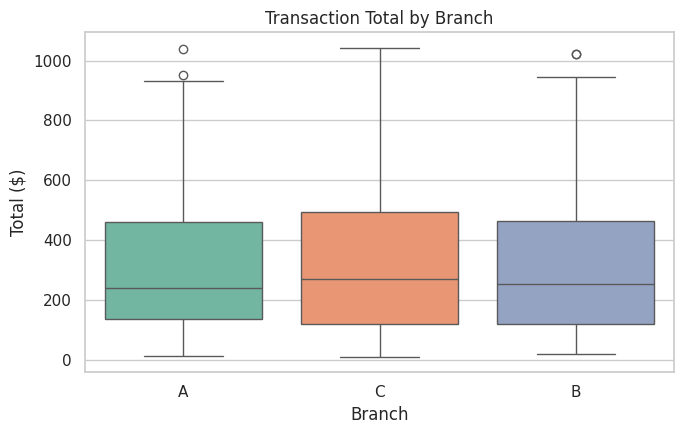

In [29]:
# 6. Box plot - basket size by branch
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='Branch', y='Total', palette='Set2')
plt.title('Transaction Total by Branch'); plt.xlabel('Branch'); plt.ylabel('Total ($)')
save('07_box_total_branch')

The three branches have almost the same spread and median. The few high-value outliers appear in every branch.

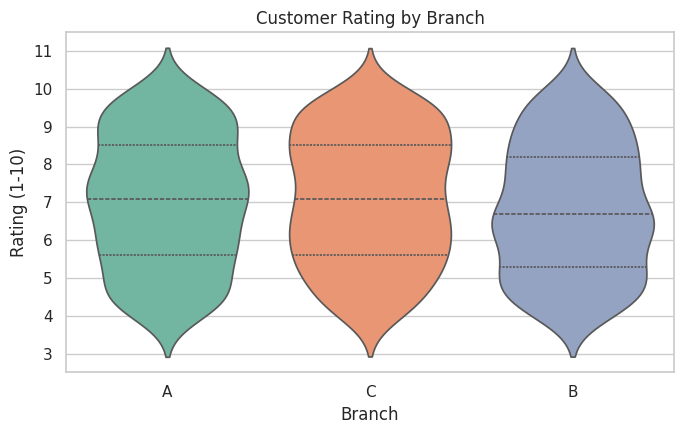

In [30]:
# 7. Violin plot - rating by branch
plt.figure(figsize=(7,4.5))
sns.violinplot(data=df, x='Branch', y='Rating', palette='Set2', inner='quartile')
plt.title('Customer Rating by Branch'); plt.xlabel('Branch'); plt.ylabel('Rating (1-10)')
save('08_violin_rating_branch')

Branch B has a slightly lower centre of ratings than A and C. I test later whether this is real or just chance.

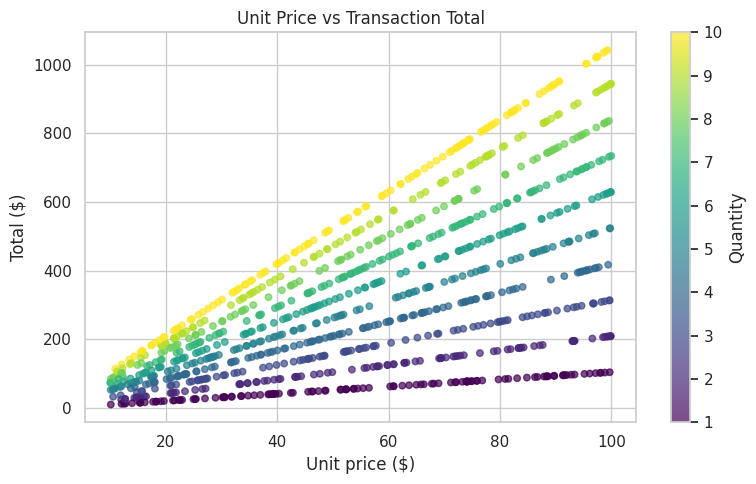

In [31]:
# 8. Scatter plot - unit price vs total, coloured by quantity
plt.figure(figsize=(8,5))
sc = plt.scatter(df['Unit price'], df['Total'], c=df['Quantity'], cmap='viridis', alpha=.7, s=22)
plt.colorbar(sc, label='Quantity')
plt.title('Unit Price vs Transaction Total'); plt.xlabel('Unit price ($)'); plt.ylabel('Total ($)')
save('09_scatter_price_total')

Colour gives the story: for the same unit price, more items means a higher total. The fan shape is exactly price x quantity.

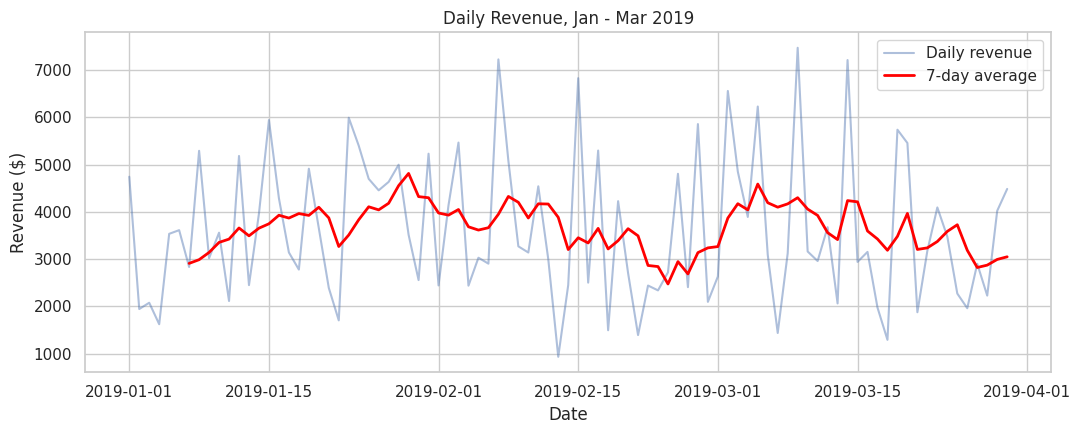

In [32]:
# 9. Line chart - daily revenue with a 7-day average
daily = df.groupby('Date')['Total'].sum()
plt.figure(figsize=(11,4.5))
plt.plot(daily.index, daily.values, alpha=.45, label='Daily revenue')
plt.plot(daily.index, daily.rolling(7).mean(), color='red', lw=2, label='7-day average')
plt.title('Daily Revenue, Jan - Mar 2019'); plt.xlabel('Date'); plt.ylabel('Revenue ($)'); plt.legend()
save('10_line_daily_revenue')

Daily revenue is very jumpy, so the 7-day average is more useful. There is no steady growth. Sales move up and down around the same level through the quarter.

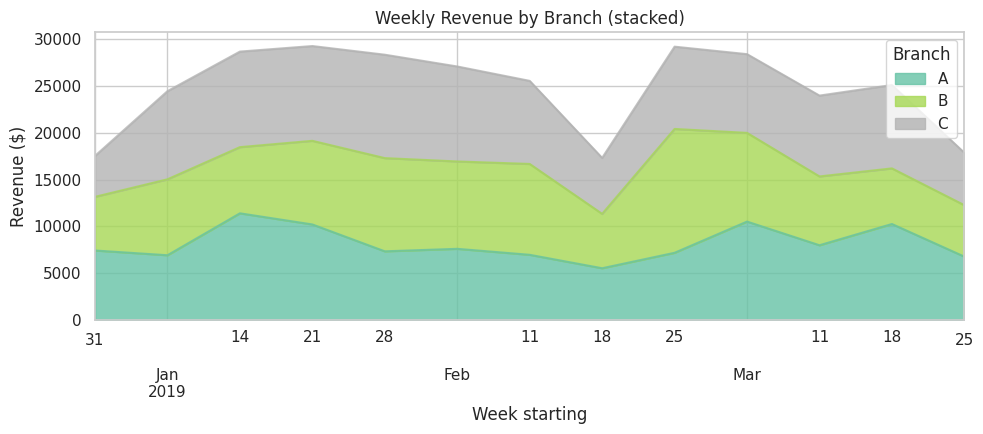

In [33]:
# 10. Area chart - weekly revenue stacked by branch
weekly = df.pivot_table(index='Week', columns='Branch', values='Total', aggfunc='sum').fillna(0)
weekly.plot.area(figsize=(10,4.5), alpha=.8, colormap='Set2')
plt.title('Weekly Revenue by Branch (stacked)'); plt.xlabel('Week starting'); plt.ylabel('Revenue ($)')
save('11_area_weekly_branch')

The first and last weeks look low only because they are partial weeks in the data. No branch dominates consistently, since the leading branch changes from week to week.

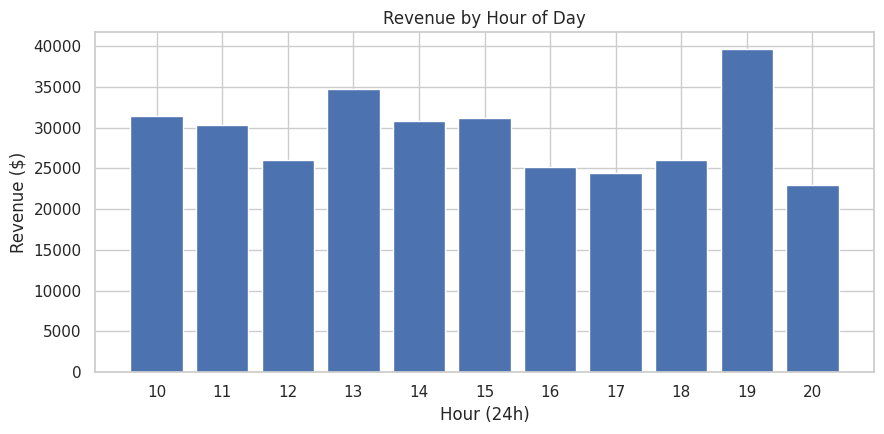

      transactions    revenue
Hour                         
19             113  39699.513
13             103  34723.227
10             101  31421.481


In [34]:
# 11. Hour of day
hr = df.groupby('Hour').agg(transactions=('Total','size'), revenue=('Total','sum'))
fig, ax = plt.subplots(figsize=(9,4.5))
ax.bar(hr.index, hr['revenue'], color='#4C72B0')
ax.set_title('Revenue by Hour of Day'); ax.set_xlabel('Hour (24h)'); ax.set_ylabel('Revenue ($)'); ax.set_xticks(hr.index)
save('12_bar_hour')
print(hr.sort_values('revenue', ascending=False).head(3))

There is a clear evening peak at 19:00 (the single best hour). The quietest times are 16:00-17:00 and 20:00.

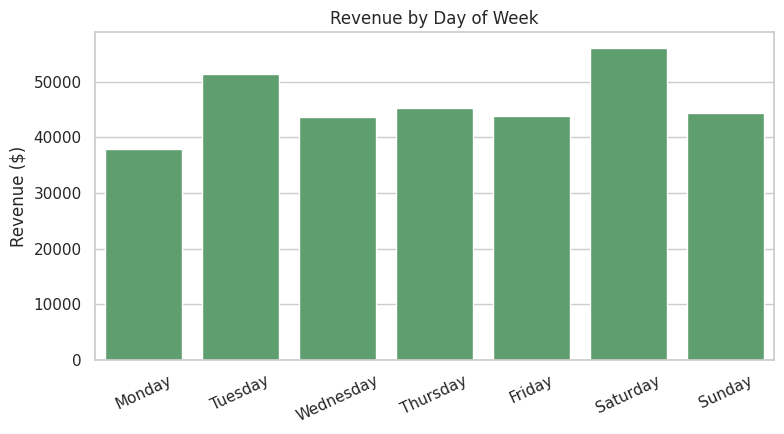

In [35]:
# 12. Day of week
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wd = df.groupby('Weekday')['Total'].sum().reindex(order)
plt.figure(figsize=(8,4.5))
sns.barplot(x=wd.index, y=wd.values, color='#55A868')
plt.title('Revenue by Day of Week'); plt.xlabel(''); plt.ylabel('Revenue ($)'); plt.xticks(rotation=25)
save('13_bar_weekday')

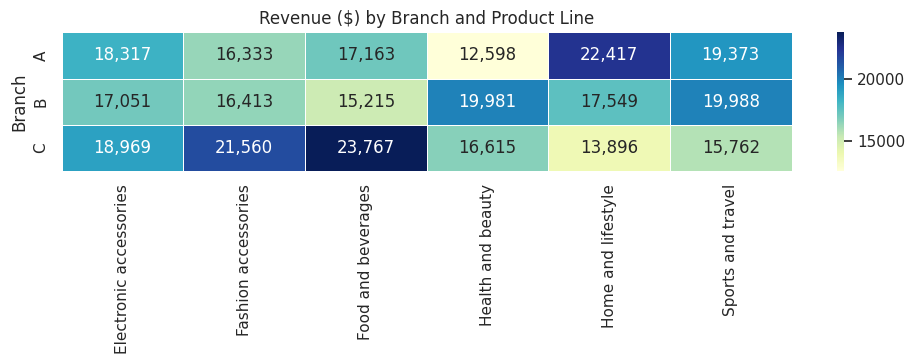

In [36]:
# 13. Heatmap - revenue by branch and product line
hm = df.pivot_table(index='Branch', columns='Product line', values='Total', aggfunc='sum')
plt.figure(figsize=(10,3.8))
sns.heatmap(hm, annot=True, fmt=',.0f', cmap='YlGnBu', linewidths=.5)
plt.title('Revenue ($) by Branch and Product Line'); plt.ylabel('Branch'); plt.xlabel('')
save('14_heatmap_branch_product')

This is where the branches look most different: Branch B is strong in Health and beauty, Branch C in Food and beverages and Fashion, and Branch A in Home and lifestyle (where C is weakest). In Part 6 I test whether this pattern is statistically solid.

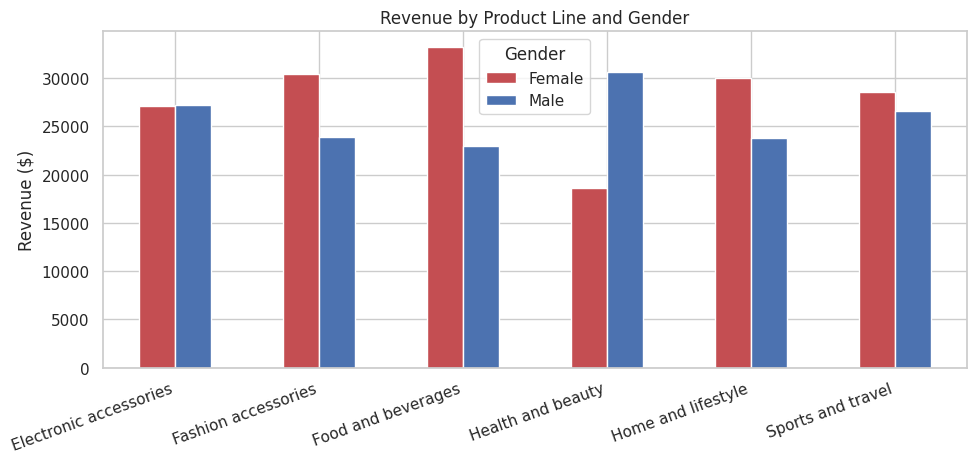

In [37]:
# 14. Grouped bar - gender x product line revenue
g = df.pivot_table(index='Product line', columns='Gender', values='Total', aggfunc='sum')
g.plot.bar(figsize=(10,4.8), color=['#C44E52','#4C72B0'])
plt.title('Revenue by Product Line and Gender'); plt.xlabel(''); plt.ylabel('Revenue ($)'); plt.xticks(rotation=20, ha='right')
save('15_bar_gender_product')

In this sample women spend more on Food and beverages, Fashion and Home, men spend more on Health and beauty, and Electronics is equal. Part 6 tests whether these gaps are strong enough to trust.

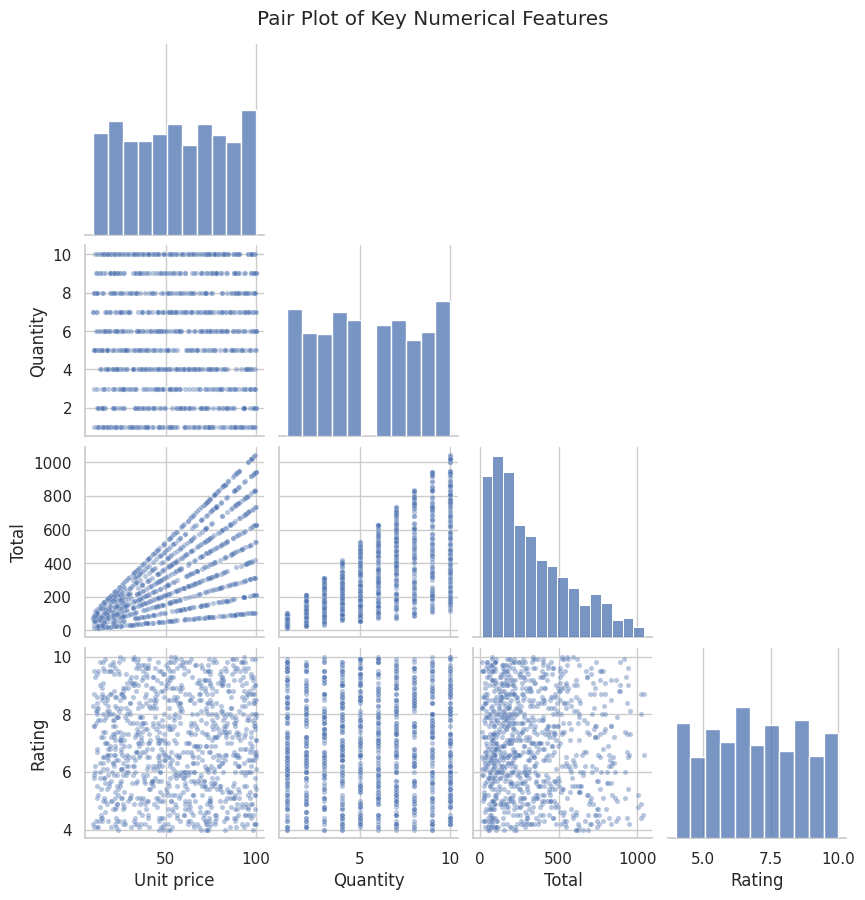

In [38]:
# 15. Pair plot of the numerical features
pp = sns.pairplot(df[['Unit price','Quantity','Total','Rating']], corner=True, plot_kws={'alpha':.4, 's':14}, height=2.2)
pp.fig.suptitle('Pair Plot of Key Numerical Features', y=1.02)
pp.savefig('graphs/16_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()

The pair plot confirms the correlation result: `Total` is linked to price and quantity, and `Rating` shows no pattern against anything.

## Part 6 - Business Insights
Differences between groups can easily be random in a dataset this size, so before writing insights I test the important ones. A p-value above 0.05 means I cannot claim the difference is real, and I will say so in the insights.

In [39]:
member = df[df['Customer type']=='Member']; normal = df[df['Customer type']=='Normal']
female = df[df['Gender']=='Female']; male = df[df['Gender']=='Male']

tests = {
 'Basket size: Member vs Normal (Mann-Whitney)': stats.mannwhitneyu(member['Total'], normal['Total']).pvalue,
 'Basket size: Female vs Male (Mann-Whitney)'  : stats.mannwhitneyu(female['Total'], male['Total']).pvalue,
 'Basket size across Branches (ANOVA)'          : stats.f_oneway(*[x['Total'] for _, x in df.groupby('Branch')]).pvalue,
 'Rating across Branches (ANOVA)'               : stats.f_oneway(*[x['Rating'] for _, x in df.groupby('Branch')]).pvalue,
 'Basket size across Product lines (ANOVA)'     : stats.f_oneway(*[x['Total'] for _, x in df.groupby('Product line')]).pvalue,
 'Rating across Product lines (ANOVA)'          : stats.f_oneway(*[x['Rating'] for _, x in df.groupby('Product line')]).pvalue,
}
ct = pd.crosstab(df['Product line'], df['Gender'])
tests['Product line mix differs by Gender (chi-square)'] = stats.chi2_contingency(ct)[1]
ct2 = pd.crosstab(df['Branch'], df['Product line'])
tests['Product line mix differs by Branch (chi-square)'] = stats.chi2_contingency(ct2)[1]
pd.Series(tests).round(3).to_frame('p-value').assign(significant=lambda d: d['p-value'] < 0.05)

,p-value,significant
Basket size: Member vs Normal (Mann-Whitney),0.591,False
Basket size: Female vs Male (Mann-Whitney),0.101,False
Basket size across Branches (ANOVA),0.413,False
Rating across Branches (ANOVA),0.126,False
Basket size across Product lines (ANOVA),0.890,False
Rating across Product lines (ANOVA),0.746,False
Product line mix differs by Gender (chi-square),0.332,False
Product line mix differs by Branch (chi-square),0.316,False


In [40]:
# Numbers I quote in the insights
print('Total revenue: %.2f | avg basket: %.2f | median basket: %.2f' % (df.Total.sum(), df.Total.mean(), df.Total.median()))
print('Share of revenue by branch %:'); print((df.groupby('Branch').Total.sum()/df.Total.sum()*100).round(1))
print('\nShare of revenue by payment %:'); print((df.groupby('Payment').Total.sum()/df.Total.sum()*100).round(1))
print('\nRating <5: %.1f%% | rating >=9: %.1f%%' % ((df.Rating<5).mean()*100, (df.Rating>=9).mean()*100))
days = df.groupby('Month').agg(rev=('Total','sum'), days=('Date','nunique'))
days['rev per trading day'] = (days.rev/days.days).round(0); print('\n', days)
print('\nAverage quantity by product line:'); print(df.groupby('Product line').Quantity.mean().round(2).sort_values())
print('\nAverage quantity by gender:'); print(df.groupby('Gender').Quantity.mean().round(2))
print('\nTotal by gender x customer type:'); print(df.pivot_table(index='Customer type', columns='Gender', values='Total', aggfunc='mean').round(1))
print('\nWeekday revenue:'); print(df.groupby('Weekday').Total.sum().reindex(order).round(0))
print('\nGender x product revenue:'); print(g.round(0))

Total revenue: 322966.75 | avg basket: 322.97 | median basket: 253.85
Share of revenue by branch %:
Branch
A    32.9
B    32.9
C    34.2
Name: Total, dtype: float64

Share of revenue by payment %:
Payment
Cash           34.7
Credit card    31.2
Ewallet        34.1
Name: Total, dtype: float64

Rating <5: 15.3% | rating >=9: 16.6%

                  rev  days  rev per trading day
Month                                          
February   97219.374    28               3472.0
January   116291.868    31               3751.0
March     109455.507    30               3649.0

Average quantity by product line:
Product line
Fashion accessories       5.07
Food and beverages        5.47
Sports and travel         5.54
Health and beauty         5.62
Home and lifestyle        5.69
Electronic accessories    5.71
Name: Quantity, dtype: float64

Average quantity by gender:
Gender
Female    5.73
Male      5.29
Name: Quantity, dtype: float64

Total by gender x customer type:
Gender         Female   Male
Cu

### 16 Business Insights (each backed by the output above)

1. **Revenue is evenly spread across branches.** Total revenue is about $322,967. Branch C leads with $110.6k (34.2%), then A with $106.2k and B with $106.2k. The ANOVA on basket size gives p = 0.41, so the branch gap is small and mostly comes from Branch C's slightly bigger average basket ($337 vs $312 and $320).
2. **Baskets are right-skewed.** The average basket is $323 but the median is only $254, so a minority of large purchases lifts the mean. The top 10% of transactions bring in about 26% of all revenue.
3. **Basket value is driven by quantity and price separately.** `Total` correlates with `Quantity` (0.71) and `Unit price` (0.63), while price and quantity are unrelated to each other (0.01). Customers do not cut quantity when prices are higher, so both are separate levers for growth.
4. **Customer rating is not explained by anything in the data.** Rating has |r| < 0.04 with price, quantity, total and hour. Satisfaction (average 6.97) does not depend on how much someone spends, so the drivers must be things not recorded here, like service or waiting time.
5. **About 1 in 6 customers is unhappy and 1 in 6 is delighted.** 15.3% of ratings are below 5 and 16.6% are 9 or above. Ratings never go below 4, so the scale is used in a narrow range.
6. **Branch B has the lowest satisfaction.** Its average rating is 6.82 vs 7.07 (C) and 7.03 (A). The test gives p = 0.13, so it is *not* statistically proven, but it is the one branch worth watching.
7. **Food and beverages is the top category, Health and beauty the weakest.** Food and beverages earns $56.1k, Health and beauty $49.2k. Basket sizes across product lines are statistically the same (p = 0.89), so the ranking is due to how many transactions each line gets (174 vs 152).
8. **Women and men differ in category spending, but the evidence is weak.** Women spend more on Food and beverages ($33.2k vs $23.0k), Fashion ($30.4k vs $23.9k) and Home and lifestyle ($30.0k vs $23.8k), while men spend more on Health and beauty ($30.6k vs $18.6k). Electronics is equal. However, the chi-square test on category mix by gender gives p = 0.33, so with only 1,000 rows this could be chance. I treat it as a hypothesis worth testing, not a proven fact. Women also buy slightly more items per basket (5.73 vs 5.29), but their basket size gap is not significant either (p = 0.10).
9. **Branches show different category strengths, again not proven.** Branch B earns $20.0k in Health and beauty vs $12.6k in A. Branch C earns $23.8k in Food and beverages but only $13.9k in Home and lifestyle, while A earns $22.4k there. The chi-square test on category mix by branch gives p = 0.32, so these gaps may be random variation. They are good places to run small experiments, not to make big changes.
10. **The evening is the busiest time.** 19:00 is the best hour with 113 transactions and about $39.7k. The slowest hours are 16:00-17:00 and 20:00 (roughly $23-25k each, against $39.7k at 19:00). Staffing and stock should follow this curve.
11. **Saturday is the best day and Monday the worst.** Saturday brings $56.1k, Monday only $37.9k. Monday also has the fewest transactions (125) and the smallest basket quantity (5.10).
12. **Monthly sales were flat to slightly down, not growing.** January $116.3k, March $109.5k, February $97.2k. February is shorter, so I compared per trading day: roughly $3.7k (Jan), $3.5k (Feb), $3.6k (Mar). There is no growth trend in the quarter.
13. **The membership card does not increase spending.** Members and normal customers are split almost 50/50 (501 vs 499), and their average baskets are $327.8 and $318.1 (p = 0.59, not significant). Ratings are also the same. Membership is not currently changing behaviour.
14. **Payment methods are balanced, with cash slightly ahead.** Cash brings 34.7% of revenue, Ewallet 34.1% and Credit card 31.2%. Average baskets are within $7 of each other, so payment method does not signal who spends more.
15. **High-value outliers are genuine and spread across the stores.** 9 baskets exceed the IQR upper fence (max $1,042.65). Every one of them is 10 items at a unit price of about $95-99, so they are real maximum-size purchases and not data errors. They appear in all three branches and in five of the six categories, so these buyers are worth treating as VIPs.
16. **The profit columns carry no information.** `gross income` equals the 5% tax amount and the gross margin is a constant 4.7619% for every row. Because of this the dataset cannot show which category or branch is actually more profitable, which is a limitation of the data itself.

## Part 7 - Business Improvement Recommendations
Each recommendation is tied to a specific finding above.

1. **Make the membership programme earn its cost (Insight 13).** Members spend no more than normal customers, so the card is not creating value yet. I would add spend-based tiers or points that reward a larger basket (for example a bonus above $400, a level only about the top 20% of baskets reach), and track the member vs non-member basket gap every month.
2. **Staff and promote around the time-of-day curve (Insights 10 and 11).** Put the strongest staffing and fresh stock at the 19:00 peak and on Saturdays. Run time-limited offers in the quiet slots (16:00-17:00, 20:00) and on Mondays, since those are the hours with the most unused capacity.
3. **Run a Health and beauty pilot (Insights 7, 8 and 9).** It is the weakest category overall, and the gap between Branch B ($20.0k) and Branch A ($12.6k) suggests there is room to grow. Because the branch and gender differences are not statistically proven, I would test before investing: copy Branch B's range and display in Branch A for a month, run a women-focused promotion in one branch only, and compare results against the other branches.
4. **Test a Home and lifestyle fix in Branch C (Insight 9).** C earns $13.9k there compared with $22.4k in A. Review what A stocks and how it displays it, trial the same layout in C, and keep the change only if the numbers improve.
5. **Increase items per basket with bundles and multi-buy offers (Insight 3).** Quantity is one of the two independent drivers of basket value, and Fashion accessories has the lowest average quantity (5.07) with the highest unit price. "Buy 3, save 10%" style offers in that category give the largest headroom.
6. **Investigate Branch B's satisfaction and collect better feedback (Insights 4, 5 and 6).** Rating does not depend on anything we measure, so more spend or more traffic will not fix it. Start a short post-purchase survey (staff, wait time, product availability) at Branch B first, and use it to find the real drivers.
7. **Record real cost and margin per product (Insight 16).** Pricing strategy cannot be optimised when the margin is the same constant for all rows. Capture true cost by product line, then repeat this analysis on actual profit.

## Conclusion
The EDA shows a very balanced business: the three branches, six product lines, payment methods and customer types perform at similar levels, and many of the gaps are not statistically significant. The clear patterns are: (1) basket size comes from quantity and price independently, (2) there are strong time-of-day and day-of-week patterns, (3) men and women seem to prefer different categories, and (4) each branch has its own category strengths and weaknesses (these last two need more data to confirm, since the tests did not reach significance). The biggest weaknesses are that membership does not increase spending, satisfaction is not explained by any measured variable, and the dataset has no real profit information.

**Limitations:** only 3 months of data, one year, and the profit columns are calculated, not observed. Findings should be confirmed with a longer period.

*Next steps (later tasks):* feature engineering, a model to predict customer rating or basket size, and a forecast of daily sales.